Gate voltage (V) | Id (uA) | gm (uS)
   0.00            0.000000   -0.000001
   0.20           -0.000000   -0.000000
   0.40           -0.000000   -0.000000
   0.60           -0.000000    0.000002
   0.80            0.000001    0.000074
   1.00            0.000029    0.003328
   1.20            0.001332    0.153584
   1.40            0.061463    1.969864
   2.00            4.247956    7.869395
   3.00           13.603860    9.353084
   4.00           22.954125    9.350265

Linear-fit slope: 9.3531 uA/V
Estimated Vth: 1.5457 V
Maximum sampled gm: 9.3531 uS


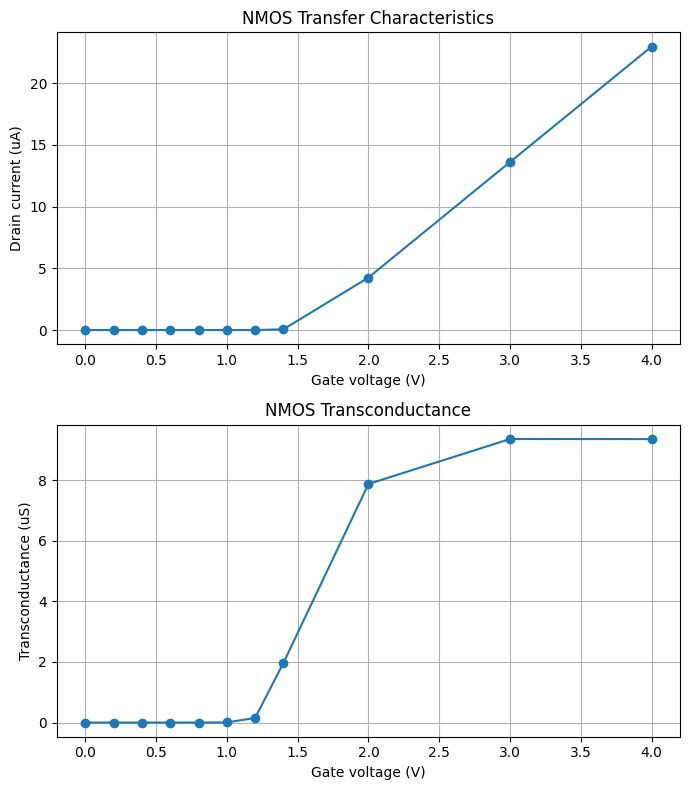

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Read the COMSOL export.
# Its first 9 lines contain metadata and expression descriptions.
raw = pd.read_csv(
    "nmos_transfer.csv",
    skiprows=9,
    header=None
)

# Each current column corresponds to one gate-voltage sweep point.
Vg = np.array([0, 0.2, 0.4, 0.6, 0.8,
               1.0, 1.2, 1.4, 2.0, 3.0, 4.0])

# Columns 0 and 1 are spatial coordinates.
# Columns 2 onward contain terminal current in microamperes.
Id_uA = raw.iloc[0, 2:13].to_numpy(dtype=float)

# Transconductance: numerical derivative.
gm_uS = np.gradient(Id_uA, Vg)

print("Gate voltage (V) | Id (uA) | gm (uS)")
for v, i, g in zip(Vg, Id_uA, gm_uS):
    print(f"{v:7.2f}          {i:10.6f}  {g:10.6f}")

# Linear extrapolation using 2 V, 3 V, and 4 V.
mask = Vg >= 2.0
m, b = np.polyfit(Vg[mask], Id_uA[mask], 1)
Vth = -b / m

print(f"\nLinear-fit slope: {m:.4f} uA/V")
print(f"Estimated Vth: {Vth:.4f} V")
print(f"Maximum sampled gm: {np.max(gm_uS):.4f} uS")

# Plot transfer characteristics and transconductance.
fig, ax = plt.subplots(2, 1, figsize=(7, 8))

ax[0].plot(Vg, Id_uA, "o-")
ax[0].set_xlabel("Gate voltage (V)")
ax[0].set_ylabel("Drain current (uA)")
ax[0].set_title("NMOS Transfer Characteristics")
ax[0].grid(True)

ax[1].plot(Vg, gm_uS, "o-")
ax[1].set_xlabel("Gate voltage (V)")
ax[1].set_ylabel("Transconductance (uS)")
ax[1].set_title("NMOS Transconductance")
ax[1].grid(True)

plt.tight_layout()
plt.show()